# Week 3 segmentation

**Pipeline**
1. **Gradient**: Prewitt on HSV S and V, max over channels.
2. **Edge segmentation**: threshold `edge_k × Otsu`.
3. **Closing** so that every frame becomes a closed outline.
4. **Week 2 post-processing**: fill holes, then opening (separates paintings joined by thin bridges).
5. **Components**: up to 2 big components that fill their bounding box.
6. **Projection rectangle** per painting (Week 2) and ordering.
7. **Evaluation** + comparison of variants.



In [16]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

DATA_DIR = Path("..") / "data" / "qsd2_w3"
IMAGE_DIR = DATA_DIR / "non_augmented"   # clean images; use DATA_DIR for the augmented ones

ids = sorted(int(p.stem) for p in IMAGE_DIR.glob("*.jpg"))
images = {i: cv2.imread(str(IMAGE_DIR / f"{i:05d}.jpg")) for i in ids}
gts = {i: cv2.imread(str(IMAGE_DIR / f"{i:05d}.png"), cv2.IMREAD_GRAYSCALE) > 0 for i in ids}
n_gt = {i: cv2.connectedComponents(gts[i].astype(np.uint8))[0] - 1 for i in ids}
print(f"{len(ids)} images | 1 painting: {sum(v == 1 for v in n_gt.values())} | 2 paintings: {sum(v == 2 for v in n_gt.values())}")

30 images | 1 painting: 21 | 2 paintings: 9


## Parameters

In [17]:
IDX = 2   # image shown step by step (2: faint small painting, 19: two close paintings, 29: frame depth)

P = {
    # 1. Gradient
    "color_space": "HSV",        # "HSV" or "LAB"
    "edge_channels": [1, 2],     # HSV: 0=H, 1=S, 2=V | LAB: 0=L, 1=a, 2=b
    "edge_operator": "prewitt",  # "prewitt", "sobel" or "laplacian"
    "blur_ksize": 1,             # Gaussian blur before the filter (odd, 1 = no blur)

    # 2. Edge segmentation
    "edge_k": 0.5,               # edge threshold = edge_k * Otsu threshold (1 = plain Otsu)

    # 3. Closing
    "close_frac": 0.02,          # closing kernel, fraction of the smallest image side

    # 4. Post-processing
    "open_frac": 0.02,           # opening after filling holes (0 = no opening)
    "erode_frac": 0.0,           # optional final erosion to tighten the masks (0 = none)

    # 5. Components
    "max_paintings": 2,
    "min_area_frac": 0.02,       # min area as a fraction of the image
    "min_rel_area": 0.15,        # min area as a fraction of the largest component
    "min_extent": 0.6,           # min area / bounding-box area

    # 6. Shape fitting
    "fit_rect": True,            # Week 2 projection rectangle per painting
    "proj_frac": 0.7,            # a row/column is kept if > proj_frac * max projection
}

## Pipeline functions
Every function receives the parameter dictionary `p`, so variants can be compared in section 7 without touching `P`.

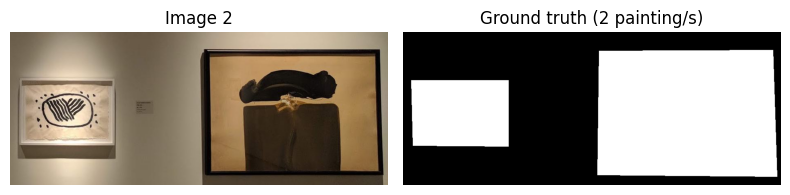

In [18]:
KERNELS = {
    "prewitt": (np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32),
                np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], np.float32)),
    "sobel": (np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
              np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32)),
}
SPACES = {"HSV": cv2.COLOR_BGR2HSV, "LAB": cv2.COLOR_BGR2LAB}


def border_mask(h, w, b):
    b = max(1, min(b, h // 2, w // 2))
    m = np.zeros((h, w), bool)
    m[:b, :] = m[-b:, :] = True
    m[:, :b] = m[:, -b:] = True
    return m


def square(frac, shape):
    n = max(2, int(frac * min(shape)))
    return cv2.getStructuringElement(cv2.MORPH_RECT, (n, n))


def fill_holes(mask):
    return ndi.binary_fill_holes(mask > 0).astype(np.uint8)


# 1. Gradient
def channel_gradient(channel, p):
    channel = channel.astype(np.float32)
    if p["blur_ksize"] > 1:
        channel = cv2.GaussianBlur(channel, (p["blur_ksize"], p["blur_ksize"]), 0)
    if p["edge_operator"] == "laplacian":
        return np.abs(cv2.Laplacian(channel, cv2.CV_32F, ksize=3))
    kx, ky = KERNELS[p["edge_operator"]]
    gx = cv2.filter2D(channel, cv2.CV_32F, kx)
    gy = cv2.filter2D(channel, cv2.CV_32F, ky)
    return np.sqrt(gx ** 2 + gy ** 2)


def gradient_magnitude(space, p):
    mag = np.zeros(space.shape[:2], np.float32)
    for c in p["edge_channels"]:
        g = channel_gradient(space[..., c], p)
        mag = np.maximum(mag, g / (g.max() + 1e-6))  # max over normalised channels
    return cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)


# 2. Edge segmentation
def edge_segmentation(grad, p):
    """Threshold the gradient at edge_k * Otsu. Returns (Otsu edges, edges used)."""
    t, _ = cv2.threshold(grad, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    otsu = (grad > t).astype(np.uint8)
    edges = (grad > p["edge_k"] * t).astype(np.uint8)
    edges[border_mask(*edges.shape, 2)] = 0  # image border is wall
    return otsu, edges


# 3. Closing
def close_edges(edges, p):
    return cv2.morphologyEx(edges, cv2.MORPH_CLOSE, square(p["close_frac"], edges.shape))


# 4. Week 2 post-processing
def post_process(mask, p):
    filled = fill_holes(mask)
    cleaned = filled
    if p["open_frac"] > 0:
        cleaned = fill_holes(cv2.morphologyEx(cleaned, cv2.MORPH_OPEN, square(p["open_frac"], mask.shape)))
    if p["erode_frac"] > 0:
        cleaned = cv2.erode(cleaned, square(p["erode_frac"], mask.shape))
    return filled, cleaned


# 5. Components
def components(mask, p):
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n < 2:
        return [], []
    largest = stats[1:, cv2.CC_STAT_AREA].max()
    info = []
    for label in range(1, n):
        x, y, w, h, area = stats[label]
        extent = area / (w * h)
        reasons = []
        if area < p["min_area_frac"] * mask.size:
            reasons.append("too small")
        if area < p["min_rel_area"] * largest:
            reasons.append("small vs largest")
        if extent < p["min_extent"]:
            reasons.append("low extent")
        info.append({"label": label, "area": int(area), "extent": round(float(extent), 3),
                     "kept": not reasons, "reasons": reasons, "mask": fill_holes(labels == label)})
    kept = sorted((c for c in info if c["kept"]), key=lambda c: -c["area"])[:p["max_paintings"]]
    kept_labels = {c["label"] for c in kept}
    for c in info:
        if c["kept"] and c["label"] not in kept_labels:
            c["kept"] = False
            c["reasons"].append(f"more than {p['max_paintings']}")
    return [c["mask"] for c in kept], info


# 6. Shape fitting and ordering
def mask_to_rect(mask, p):
    rect = np.zeros(mask.shape, np.uint8)
    if not mask.any():
        return rect
    col_prof, row_prof = mask.mean(axis=0), mask.mean(axis=1)
    cols = col_prof > p["proj_frac"] * col_prof.max()
    rows = row_prof > p["proj_frac"] * row_prof.max()
    x0, x1 = np.where(cols)[0][[0, -1]]
    y0, y1 = np.where(rows)[0][[0, -1]]
    rect[y0:y1 + 1, x0:x1 + 1] = 1
    return rect


def order_masks(masks):
    if len(masks) < 2:
        return masks
    boxes = [cv2.boundingRect(m.astype(np.uint8)) for m in masks]
    (x0, _, w0, _), (x1, _, w1, _) = boxes[0], boxes[1]
    overlap_x = min(x0 + w0, x1 + w1) - max(x0, x1)
    axis = 1 if overlap_x > 0.5 * min(w0, w1) else 0  # stacked -> sort by y
    return [masks[i] for i in sorted(range(len(masks)), key=lambda i: boxes[i][axis])]


def detect(img, p):
    """Whole pipeline, returning every intermediate step."""
    d = {"space": cv2.cvtColor(img, SPACES[p["color_space"]])}
    d["gradient"] = gradient_magnitude(d["space"], p)
    d["otsu"], d["edges"] = edge_segmentation(d["gradient"], p)
    d["closed"] = close_edges(d["edges"], p)
    d["filled"], d["cleaned"] = post_process(d["closed"], p)
    comps, d["candidates"] = components(d["cleaned"], p)
    if p["fit_rect"]:
        comps = [mask_to_rect(c, p) for c in comps]
    d["masks"] = order_masks(comps)
    return d


# Evaluation and visualisation helpers
def union(masks, shape):
    out = np.zeros(shape[:2], bool)
    for m in masks:
        out |= m > 0
    return out


def metrics(pred, gt):
    tp = np.count_nonzero(pred & gt)
    fp = np.count_nonzero(pred & ~gt)
    fn = np.count_nonzero(~pred & gt)
    pr = tp / (tp + fp) if tp + fp else 0.0
    rc = tp / (tp + fn) if tp + fn else 0.0
    return {"precision": pr, "recall": rc, "f1": 2 * pr * rc / (pr + rc) if pr + rc else 0.0,
            "iou": tp / (tp + fp + fn) if tp + fp + fn else 1.0}


def evaluate(p):
    rows, all_masks = [], {}
    for i in ids:
        masks = detect(images[i], p)["masks"]
        all_masks[i] = masks
        rows.append({"id": i, "gt_count": n_gt[i], "pred_count": len(masks),
                     **metrics(union(masks, images[i].shape), gts[i])})
    df = pd.DataFrame(rows).set_index("id")
    df["count_ok"] = df.gt_count == df.pred_count
    return df, all_masks


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show(panels, cols=None, size=4):
    cols = cols or len(panels)
    rows = int(np.ceil(len(panels) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, im) in zip(axes.flat, panels):
        ax.imshow(im, cmap=None if im.ndim == 3 else "gray")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


def overlay(img, masks, alpha=0.45):
    colors = [(255, 60, 60), (60, 160, 255), (60, 220, 60)]
    out = rgb(img).copy()
    for k, m in enumerate(masks):
        m = m.astype(np.uint8)
        color = np.array(colors[k % len(colors)])
        out[m > 0] = ((1 - alpha) * out[m > 0] + alpha * color).astype(np.uint8)
        contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, contours, -1, color.tolist(), 3)
        x, y, w, h = cv2.boundingRect(m)
        cv2.putText(out, str(k + 1), (x + w // 2, y + h // 2), cv2.FONT_HERSHEY_SIMPLEX, 2, (255, 255, 255), 5)
    return out


img, gt = images[IDX], gts[IDX]
d = detect(img, P)
show([(f"Image {IDX}", rgb(img)), (f"Ground truth ({n_gt[IDX]} painting/s)", gt)])

## 1. Gradient (Prewitt on each channel, max over channels)
The last panel shows the same gradient with a Gaussian blur of 5: the edges get thicker.

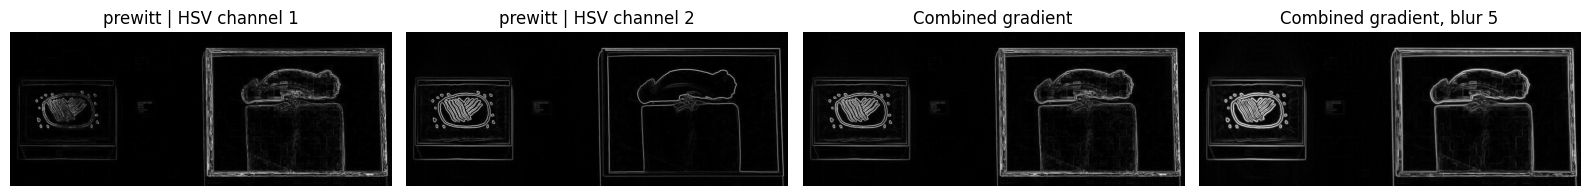

In [19]:
show([(f"{P['edge_operator']} | {P['color_space']} channel {c}", channel_gradient(d["space"][..., c], P))
      for c in P["edge_channels"]] + [("Combined gradient", d["gradient"]),
                                      ("Combined gradient, blur 5", gradient_magnitude(d["space"], {**P, "blur_ksize": 5}))])

## 2. Edge segmentation: lower threshold
- **Plain Otsu**: the threshold is set by the strongest edges of the image, faint frames are lost.
- **`edge_k` × Otsu**: faint frames survive (some wall texture too, removed later by the opening and the component filters).

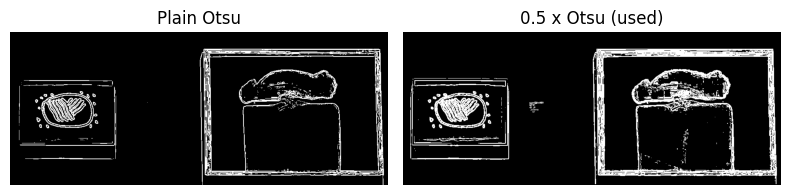

In [20]:
show([("Plain Otsu", d["otsu"]), (f"{P['edge_k']} x Otsu (used)", d["edges"])])

## 3. Closing
Joins the gaps of each frame so the outline is closed and can be filled.

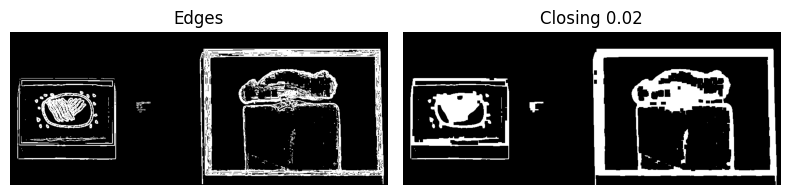

In [21]:
show([("Edges", d["edges"]), (f"Closing {P['close_frac']}", d["closed"])])

## 4. Week 2 post-processing: fill holes + opening
The opening after filling removes thin structures and separates paintings joined by a thin bridge. An optional erosion (`erode_frac`) tightens the result.

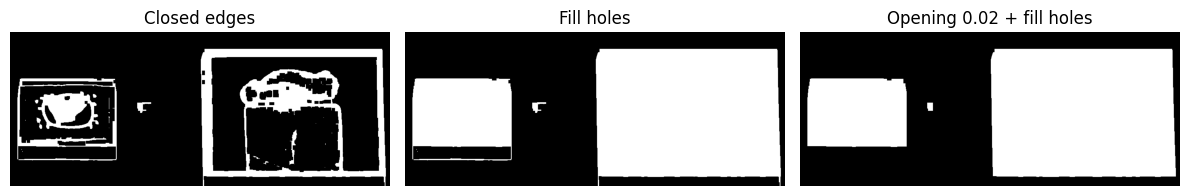

In [22]:
show([("Closed edges", d["closed"]), ("Fill holes", d["filled"]),
      (f"Opening {P['open_frac']} + fill holes" + (f" + erosion {P['erode_frac']}" if P["erode_frac"] else ""), d["cleaned"])])

## 5. Components
Green = kept, red = rejected (reason in the table).

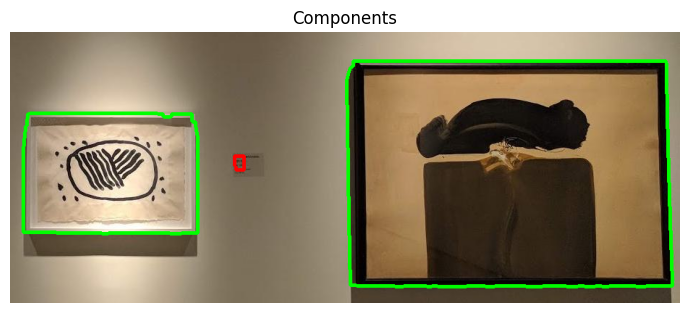

,label,area,extent,kept,reasons
0,1,138192,0.982,True,[]
1,2,39768,0.984,True,[]
2,3,269,0.961,False,"[too small, small vs largest]"


In [23]:
vis = rgb(img).copy()
for c in d["candidates"]:
    contours, _ = cv2.findContours(c["mask"].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis, contours, -1, (0, 255, 0) if c["kept"] else (255, 0, 0), 3)
show([("Components", vis)], size=7)
pd.DataFrame([{k: v for k, v in c.items() if k != "mask"} for c in d["candidates"]]).sort_values("area", ascending=False).head(10)

## 6. Projection rectangle per painting + ordering

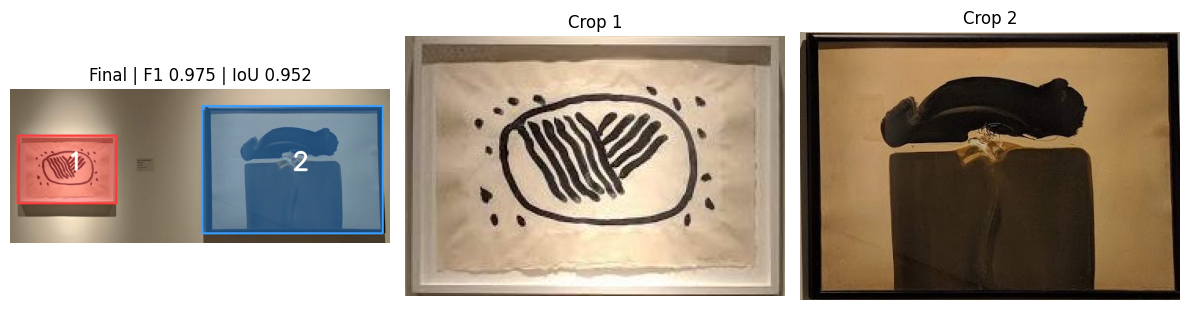

In [24]:
m = metrics(union(d["masks"], img.shape), gt)
crops = []
for mask in d["masks"]:
    ys, xs = np.nonzero(mask)
    crops.append(img[ys.min():ys.max() + 1, xs.min():xs.max() + 1])
show([(f"Final | F1 {m['f1']:.3f} | IoU {m['iou']:.3f}", overlay(img, d["masks"]))]
     + [(f"Crop {k + 1}", rgb(c)) for k, c in enumerate(crops)])

## 7. Evaluation on the whole dataset

In [25]:
results, all_masks = evaluate(P)
print(f"Count accuracy: {results.count_ok.sum()}/{len(results)}")
display(results[["precision", "recall", "f1", "iou"]].mean().to_frame("mean").T)
results.sort_values("f1").head(10)

Count accuracy: 30/30


,precision,recall,f1,iou
mean,0.965561,0.98618,0.975151,0.952278


,gt_count,pred_count,precision,recall,f1,iou,count_ok
id,,,,,,,
29,2,2,0.831984,0.995021,0.906228,0.828535,True
23,1,1,1.000000,0.862820,0.926359,0.862820,True
6,2,2,0.900348,0.989146,0.942660,0.891540,True
20,1,1,0.951192,0.948903,0.950046,0.904845,True
5,2,2,0.926079,1.000000,0.961621,0.926079,True
4,1,1,0.932888,0.996429,0.963612,0.929779,True
25,1,1,0.931566,1.000000,0.964571,0.931566,True
27,1,1,0.942815,0.993888,0.967678,0.937380,True
7,2,2,0.940991,0.998168,0.968737,0.939369,True


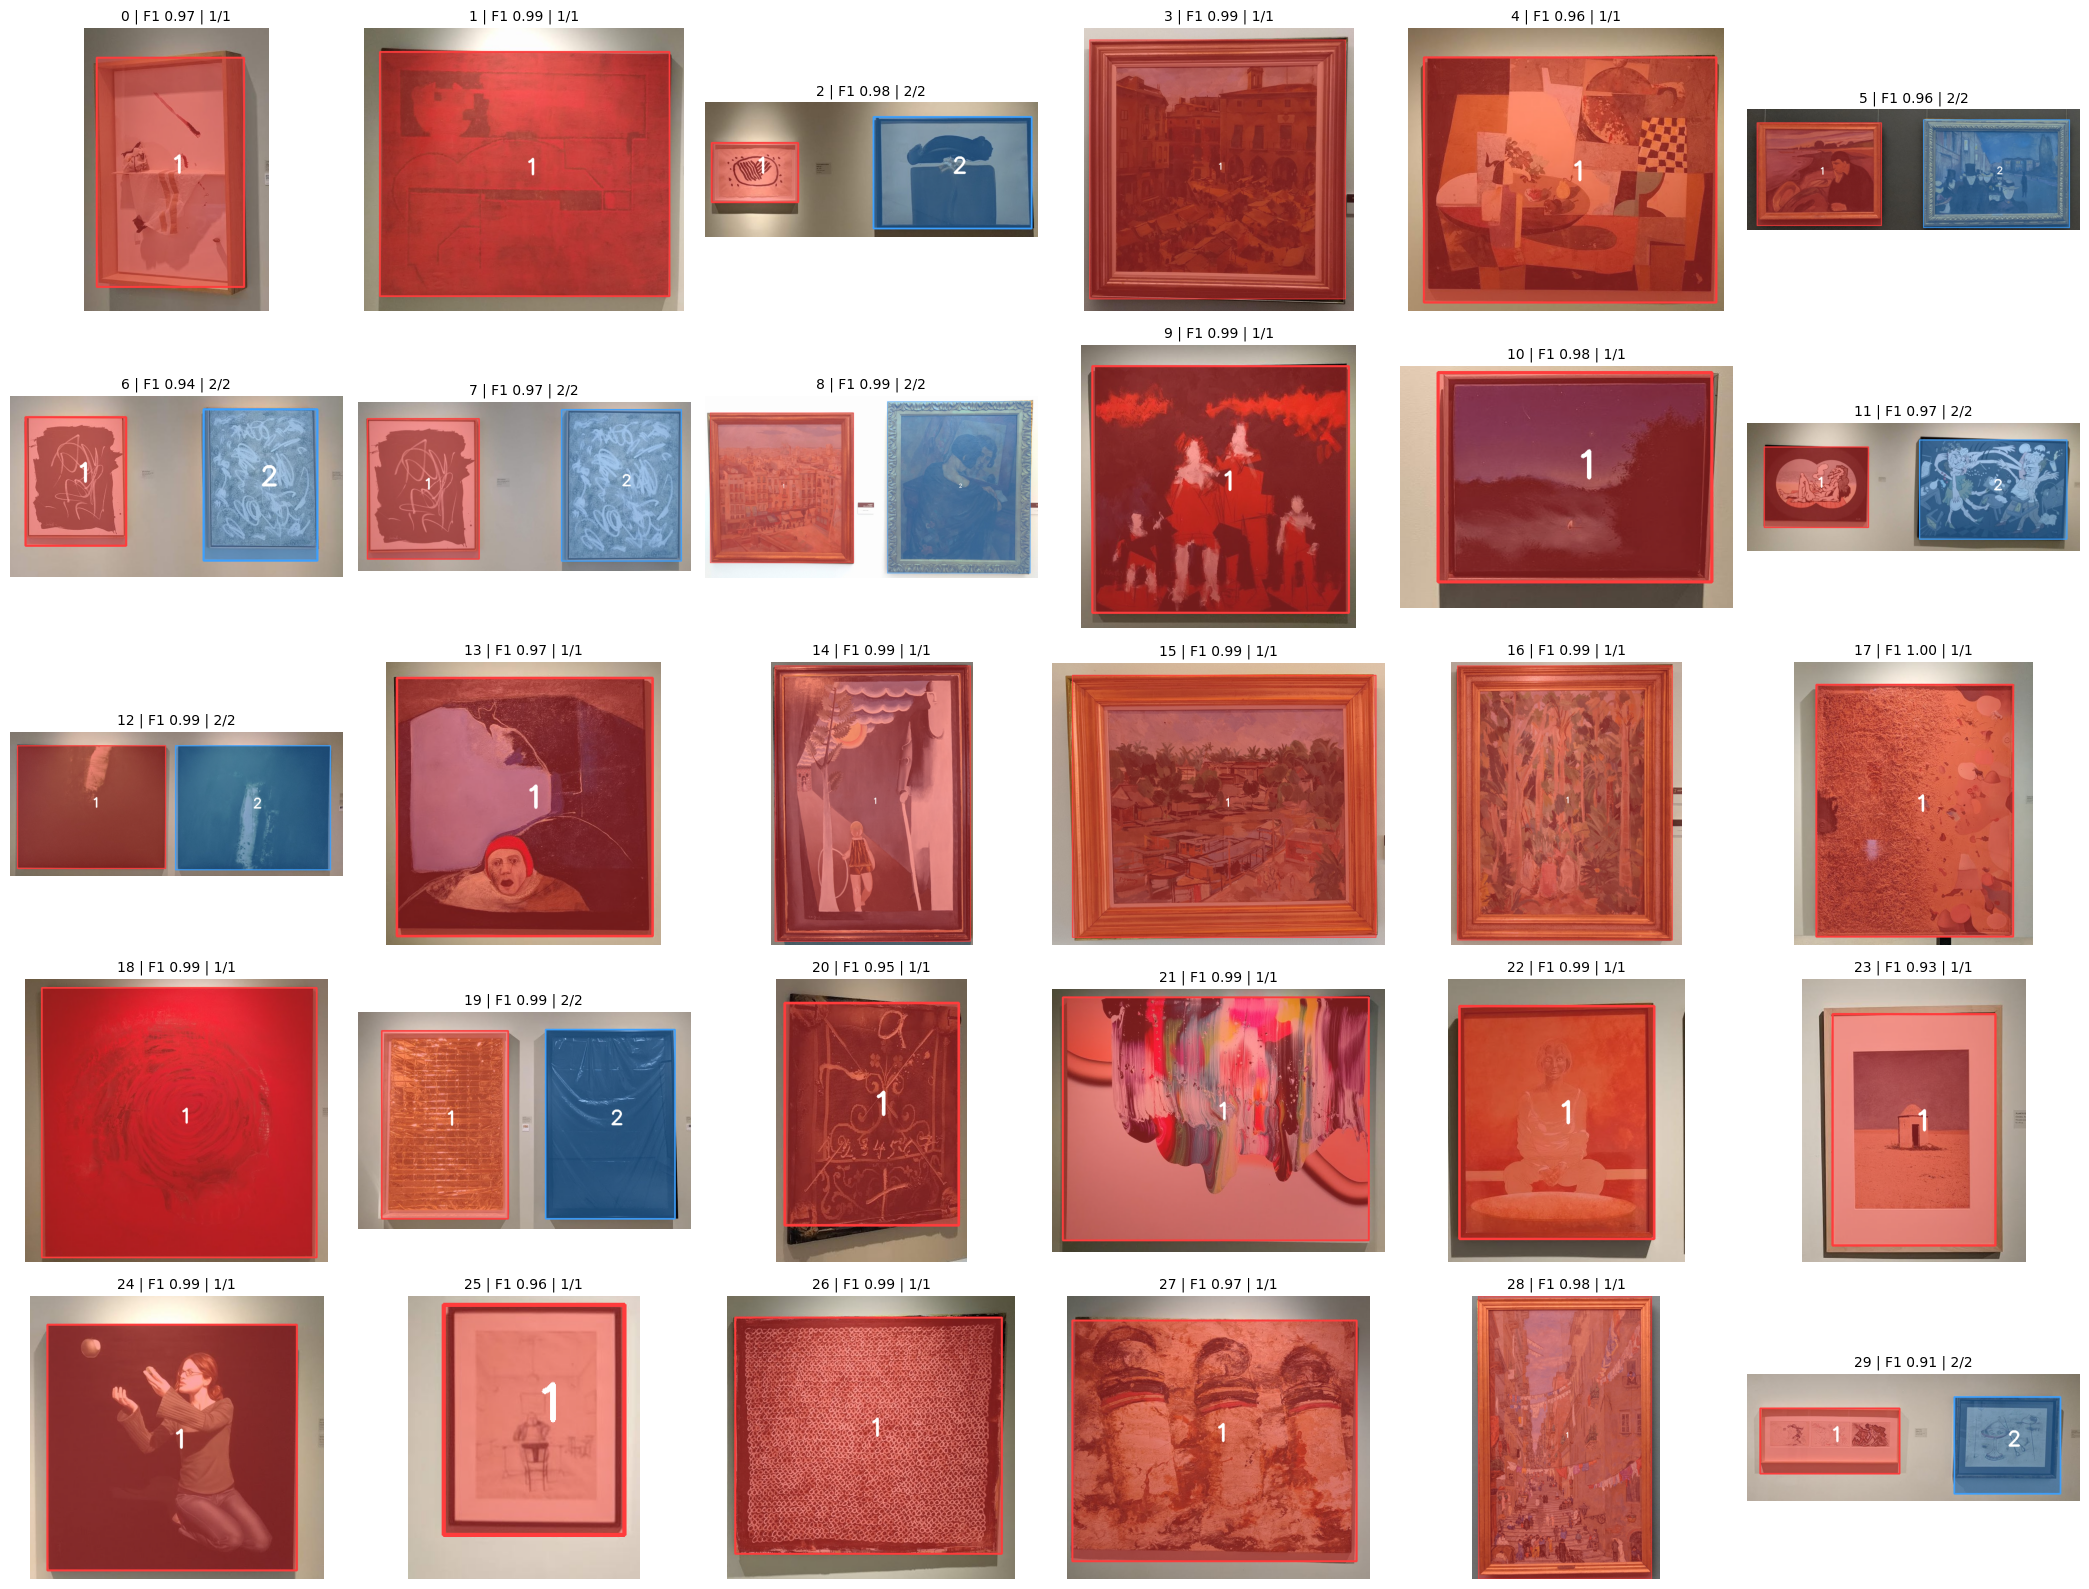

In [26]:
cols = 6
rows_n = int(np.ceil(len(ids) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(3.5 * cols, 3.2 * rows_n))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, ids):
    r = results.loc[i]
    ax.imshow(overlay(images[i], all_masks[i]))
    ax.set_title(f"{i} | F1 {r.f1:.2f} | {r.pred_count}/{r.gt_count}",
                 color="black" if r.count_ok else "red", fontsize=10)
plt.tight_layout()
plt.show()

### Variants
Each row changes some parameters of `P`. It shows why every piece of the pipeline is there; add your own rows to try ideas.

In [27]:
variants = {
    "selected (P)": {},
    "plain Otsu (edge_k 1)": {"edge_k": 1.0},
    "edge_k 0.8": {"edge_k": 0.8},
    "edge_k 0.4": {"edge_k": 0.4},
    "blur 5 (previous notebook)": {"blur_ksize": 5},
    "blur 3": {"blur_ksize": 3},
    "proj_frac 0.5 (Week 2 value)": {"proj_frac": 0.5},
    "proj_frac 0.9": {"proj_frac": 0.9},
    "no opening": {"open_frac": 0},
    "erosion 0.005": {"erode_frac": 0.005},
    "closing 0.01": {"close_frac": 0.01},
    "sobel": {"edge_operator": "sobel"},
}
rows = []
for name, change in variants.items():
    df, _ = evaluate({**P, **change})
    rows.append({"variant": name, "paintings ok": f"{df.count_ok.sum()}/{len(df)}",
                 **df[["precision", "recall", "f1", "iou"]].mean().round(4).to_dict()})
    print(f"done: {name}")
pd.DataFrame(rows).set_index("variant")

done: selected (P)
done: plain Otsu (edge_k 1)
done: edge_k 0.8
done: edge_k 0.4
done: blur 5 (previous notebook)
done: blur 3
done: proj_frac 0.5 (Week 2 value)
done: proj_frac 0.9
done: no opening
done: erosion 0.005
done: closing 0.01
done: sobel


,paintings ok,precision,recall,f1,iou
variant,,,,,
selected (P),30/30,0.9656,0.9862,0.9752,0.9523
plain Otsu (edge_k 1),29/30,0.9830,0.9104,0.9362,0.8948
edge_k 0.8,30/30,0.9757,0.9644,0.9660,0.9407
edge_k 0.4,30/30,0.9545,0.9917,0.9723,0.9468
blur 5 (previous notebook),30/30,0.9525,0.9930,0.9719,0.9461
blur 3,30/30,0.9543,0.9921,0.9724,0.9470
proj_frac 0.5 (Week 2 value),30/30,0.9582,0.9906,0.9735,0.9492
proj_frac 0.9,30/30,0.9728,0.9460,0.9544,0.9200
no opening,30/30,0.9608,0.9865,0.9728,0.9479
